# Security arms transfers: SIPRI development

## Purpose

This notebook develops and validates the SIPRI arms-transfer component of the US-China Closeness Index.

For eligible country-year observations, the baseline candidate is the net US-versus-China share of global major-arms imports over the preceding five years:

$$
\text{arms transfer score}_{i,t}
=
\frac{US^{(5)}_{i,t}-China^{(5)}_{i,t}}
     {Global^{(5)}_{i,t}}.
$$

Two diagnostics are retained:

$$
\text{direction}_{i,t}
=
\frac{US^{(5)}_{i,t}-China^{(5)}_{i,t}}
     {US^{(5)}_{i,t}+China^{(5)}_{i,t}},
$$

$$
\text{anchor exposure}_{i,t}
=
\frac{US^{(5)}_{i,t}+China^{(5)}_{i,t}}
     {Global^{(5)}_{i,t}}.
$$

Where both diagnostics are defined:

$$
\text{arms transfer score}
=
\text{direction}\times\text{anchor exposure}.
$$

The notebook uses the production builder's functions so that exploration and production logic do not diverge. It does not write production outputs unless the final export cell is explicitly run.

## 1. Setup and repository paths

All paths are repository-relative. Run the notebook from the repository root, or allow the path-discovery cell to locate it from the notebook directory.

In [17]:
from __future__ import annotations

import importlib.util
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "src" / "data" / "build_sipri_arms_transfers.py").exists():
            return candidate
    raise FileNotFoundError("Could not locate the repository root.")


REPO_ROOT = find_repo_root(Path.cwd().resolve())
BUILDER_PATH = REPO_ROOT / "src" / "data" / "build_sipri_arms_transfers.py"

spec = importlib.util.spec_from_file_location("build_sipri_arms_transfers", BUILDER_PATH)
if spec is None or spec.loader is None:
    raise ImportError(f"Could not import {BUILDER_PATH}")
sipri = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = sipri
spec.loader.exec_module(sipri)

US_FILE = REPO_ROOT / "data" / "raw" / "us_transfers.csv"
CHINA_FILE = REPO_ROOT / "data" / "raw" / "cn_transfers.csv"
GLOBAL_FILE = REPO_ROOT / "data" / "raw" / "global_transfers.csv"
COUNTRY_MASTER_FILE = (
    REPO_ROOT
    / "outputs"
    / "tables"
    / "relations_condition"
    / "relationship_condition_country_master.csv"
)

paths = {
    "repository_root": REPO_ROOT,
    "builder": BUILDER_PATH,
    "us_export": US_FILE,
    "china_export": CHINA_FILE,
    "global_export": GLOBAL_FILE,
    "country_master": COUNTRY_MASTER_FILE,
}

missing_paths = [str(path) for path in paths.values() if not Path(path).exists()]
if missing_paths:
    raise FileNotFoundError(f"Required paths are missing: {missing_paths}")

display_paths = {
    name: (
        "."
        if path == REPO_ROOT
        else path.relative_to(REPO_ROOT).as_posix()
    )
    for name, path in paths.items()
}

pd.Series(display_paths, name="repository_relative_path")

repository_root                                                    .
builder                       src/data/build_sipri_arms_transfers.py
us_export                                  data/raw/us_transfers.csv
china_export                               data/raw/cn_transfers.csv
global_export                          data/raw/global_transfers.csv
country_master     outputs/tables/relations_condition/relationshi...
Name: repository_relative_path, dtype: object

## 2. Source inventory

The source exports should cover 1996-2025 and use the same SIPRI TIV conventions. Empty annual cells represent no identified delivery. A displayed zero represents a positive value below 0.5 million TIV and is represented by 0.25 in the baseline specification.

In [18]:
source_specs = [
    (US_FILE, "us_tiv"),
    (CHINA_FILE, "china_tiv"),
    (GLOBAL_FILE, "global_tiv"),
]

source_frames = {}
removed_frames = []
treatment_frames = []
metadata_rows = []

for filepath, value_name in source_specs:
    evidence, removed, treatment, metadata = sipri.load_sipri_export(
        filepath,
        value_name,
    )
    source_frames[value_name] = evidence
    removed_frames.append(removed)
    treatment_frames.append(treatment)
    metadata_rows.append(metadata)

source_metadata = pd.DataFrame(metadata_rows)
source_metadata["source_file"] = source_metadata["source_file"].map(
    lambda value: Path(value).relative_to(REPO_ROOT).as_posix()
)
value_treatment_audit = pd.concat(treatment_frames, ignore_index=True)
removed_nonstate_audit = pd.concat(removed_frames, ignore_index=True)

display(source_metadata)
display(value_treatment_audit)

,source_file,data_generated,header_row_zero_based,source,recipient_rows_before_removal,recipient_rows_after_removal
0,data/raw/us_transfers.csv,26 Oct 2026 12:38:58 PM,9,us_tiv,138,131
1,data/raw/cn_transfers.csv,26 Oct 2026 12:39:24 PM,9,china_tiv,85,82
2,data/raw/global_transfers.csv,26 Oct 2026 12:39:53 PM,9,global_tiv,209,179


,value_treatment,cell_count,source,rounded_zero_value
0,blank_to_zero,2205,us_tiv,0.25
1,displayed_zero_to_midpoint,48,us_tiv,0.25
2,positive_numeric,1677,us_tiv,0.25
3,blank_to_zero,1951,china_tiv,0.25
4,displayed_zero_to_midpoint,12,china_tiv,0.25
5,positive_numeric,497,china_tiv,0.25
6,blank_to_zero,1996,global_tiv,0.25
7,displayed_zero_to_midpoint,79,global_tiv,0.25
8,positive_numeric,3295,global_tiv,0.25


## 3. Removed source recipients

Source-marked armed groups, international organisations, total rows, and unknown-recipient rows are separated from the state-level processing. Policy-dependent geographic entities are not removed here. They are mapped and then governed by the project country master.

In [3]:
removed_summary = (
    removed_nonstate_audit[
        ["source", "recipient_source_name", "removal_reason"]
    ]
    .drop_duplicates()
    .sort_values(["removal_reason", "recipient_source_name", "source"])
)

display(
    removed_summary.groupby(["source", "removal_reason"], as_index=False)
    .size()
    .rename(columns={"size": "recipient_count"})
)
display(removed_summary)

,source,removal_reason,recipient_count
0,china_tiv,source_marked_nonstate,2
1,china_tiv,source_total_row,1
2,global_tiv,source_marked_nonstate,28
3,global_tiv,source_total_row,1
4,global_tiv,unknown_recipient,1
5,us_tiv,source_marked_nonstate,5
6,us_tiv,source_total_row,1
7,us_tiv,unknown_recipient,1


,source,recipient_source_name,removal_reason
210,china_tiv,African Union**,source_marked_nonstate
300,global_tiv,African Union**,source_marked_nonstate
0,us_tiv,African Union**,source_marked_nonstate
301,global_tiv,Darfur rebels (Sudan)*,source_marked_nonstate
302,global_tiv,Hamas (Palestine)*,source_marked_nonstate
303,global_tiv,Hezbollah (Lebanon)*,source_marked_nonstate
304,global_tiv,House of Representatives (Libya)*,source_marked_nonstate
305,global_tiv,Houthi rebels (Yemen)*,source_marked_nonstate
306,global_tiv,Kurdistan Regional Government (Iraq)*,source_marked_nonstate
307,global_tiv,LRA (Uganda)*,source_marked_nonstate


## 4. Country mapping and crosswalk audit

The project country master provides the main mapping authority. Explicit SIPRI aliases handle source-specific names such as `Congo`, `DR Congo`, `Viet Nam`, and `Turkiye`. The build must stop if any recipient name remains unmapped.

In [4]:
country_master = sipri.load_country_master(COUNTRY_MASTER_FILE)
lookup, mapping_reference = sipri.build_mapping_lookup(country_master)

annual_source, unmapped_names, source_name_mapping_audit = (
    sipri.merge_and_map_sources(
        [
            source_frames["us_tiv"],
            source_frames["china_tiv"],
            source_frames["global_tiv"],
        ],
        lookup,
    )
)

print(f"Unmapped source names: {len(unmapped_names)}")
if not unmapped_names.empty:
    display(unmapped_names)
else:
    print("All state-like SIPRI recipient names mapped successfully.")

mapping_consolidations = source_name_mapping_audit.loc[
    source_name_mapping_audit["source_names_per_iso3"] > 1
]
display(mapping_consolidations)

Unmapped source names: 0
All state-like SIPRI recipient names mapped successfully.


,recipient_source_name,normalized_recipient_name,iso3,source_names_per_iso3


## 5. Annual evidence and project universe

The production universe comes from the country master rather than from the set of recipients appearing in SIPRI. This retains eligible countries with no observed delivery and applies entity-specific validity intervals.

In [5]:
project_grid = sipri.create_eligible_project_grid(country_master)
annual_panel = project_grid.merge(
    annual_source,
    on=["iso3", "year"],
    how="left",
    validate="one_to_one",
)

for column in sipri.VALUE_COLUMNS:
    annual_panel[column] = annual_panel[column].fillna(0.0)

universe_summary = pd.Series(
    {
        "eligible ISO3 entities": annual_panel["iso3"].nunique(),
        "annual rows, 1996-2025 plus validity rules": len(annual_panel),
        "duplicate ISO3-year rows": annual_panel.duplicated(["iso3", "year"]).sum(),
        "US positive annual cells": int((annual_panel["us_tiv"] > 0).sum()),
        "China positive annual cells": int((annual_panel["china_tiv"] > 0).sum()),
        "Global positive annual cells": int((annual_panel["global_tiv"] > 0).sum()),
    },
    name="value",
)
universe_summary

eligible ISO3 entities                         192
annual rows, 1996-2025 plus validity rules    5737
duplicate ISO3-year rows                         0
US positive annual cells                      1690
China positive annual cells                    509
Global positive annual cells                  3268
Name: value, dtype: int64

## 6. Five-year rolling measures and baseline score

The complete source history is used for rolling calculations. The production window is then restricted to 2004-2025.

In [6]:
score_panel = sipri.add_rolling_measures(annual_panel)
exposure_violations = sipri.validate_panel(score_panel)

summary = pd.Series(
    {
        "production rows": len(score_panel),
        "production entities": score_panel["iso3"].nunique(),
        "first production year": score_panel["year"].min(),
        "last production year": score_panel["year"].max(),
        "duplicate ISO3-year rows": score_panel.duplicated(["iso3", "year"]).sum(),
        "non-missing baseline scores": score_panel["arms_transfer_score"].notna().sum(),
        "minimum baseline score": score_panel["arms_transfer_score"].min(),
        "maximum baseline score": score_panel["arms_transfer_score"].max(),
        "exposure violations": len(exposure_violations),
    },
    name="value",
)
summary

production rows                4205.0
production entities             192.0
first production year          2004.0
last production year           2025.0
duplicate ISO3-year rows          0.0
non-missing baseline scores    3262.0
minimum baseline score           -1.0
maximum baseline score            1.0
exposure violations               0.0
Name: value, dtype: float64

## 7. Observation status

A score of zero and a missing score have different meanings:

- `available`: at least one anchor supplied arms and all three measures are available;
- `no_observed_anchor_transfers`: global imports exist, but neither anchor supplied arms; the baseline score is zero and pure direction is undefined;
- `no_observed_arms_imports`: no global delivery was identified in the five-year window; the baseline score is missing.

In [7]:
status_summary = (
    score_panel.groupby("observation_status", as_index=False)
    .agg(
        country_years=("iso3", "size"),
        countries=("iso3", "nunique"),
        non_missing_scores=("arms_transfer_score", "count"),
    )
)
status_summary["share"] = status_summary["country_years"] / len(score_panel)
display(status_summary)

status_score_check = pd.crosstab(
    score_panel["observation_status"],
    score_panel["arms_transfer_score"].isna(),
    margins=True,
)
status_score_check.columns = ["score_present", "score_missing", "total"]
status_score_check

,observation_status,country_years,countries,non_missing_scores,share
0,available,2329,144,2329,0.553864
1,no_observed_anchor_transfers,933,116,933,0.221879
2,no_observed_arms_imports,943,93,0,0.224257


,score_present,score_missing,total
observation_status,,,
available,2329,0,2329
no_observed_anchor_transfers,933,0,933
no_observed_arms_imports,0,943,943
All,3262,943,4205


## 8. Baseline-score distribution

The first plot shows the material net US-versus-China share of global arms imports. The second shows pure direction among anchor transfers. Comparing them reveals how exposure to other suppliers attenuates otherwise extreme directional scores.

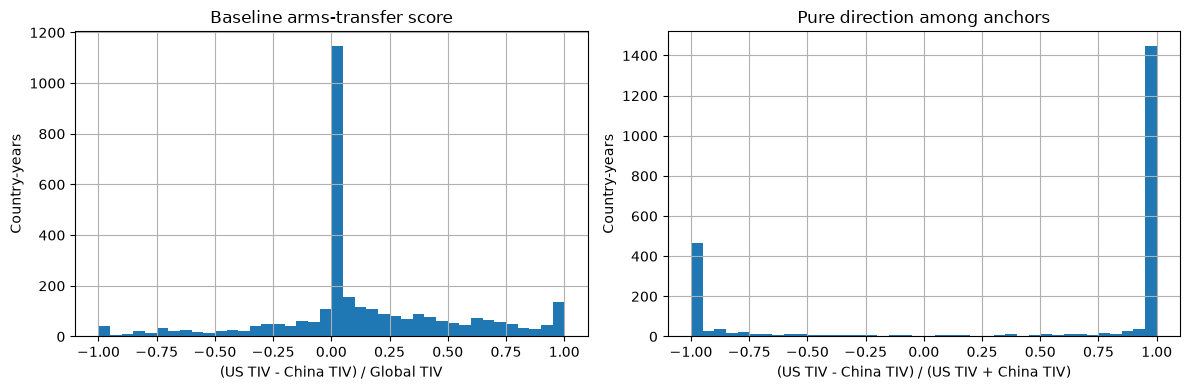

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

score_panel["arms_transfer_score"].dropna().hist(bins=40, ax=axes[0])
axes[0].set_title("Baseline arms-transfer score")
axes[0].set_xlabel("(US TIV - China TIV) / Global TIV")
axes[0].set_ylabel("Country-years")

score_panel["direction_score"].dropna().hist(bins=40, ax=axes[1])
axes[1].set_title("Pure direction among anchors")
axes[1].set_xlabel("(US TIV - China TIV) / (US TIV + China TIV)")
axes[1].set_ylabel("Country-years")

plt.tight_layout()
plt.show()

## 9. Extreme cases and attenuation

These tables inspect the most US-oriented and China-oriented material relationships, then identify cases where pure direction is extreme but anchor exposure is low.

In [9]:
analysis_columns = [
    "iso3",
    "preferred_country_name",
    "year",
    "us_tiv_5yr",
    "china_tiv_5yr",
    "global_tiv_5yr",
    "direction_score",
    "anchor_exposure_raw",
    "arms_transfer_score",
]

available_scores = score_panel.loc[
    score_panel["arms_transfer_score"].notna(),
    analysis_columns,
]

display(
    available_scores.nlargest(15, "arms_transfer_score")
    .sort_values("arms_transfer_score", ascending=False)
)
display(
    available_scores.nsmallest(15, "arms_transfer_score")
    .sort_values("arms_transfer_score")
)

attenuated = available_scores.loc[
    available_scores["direction_score"].abs().ge(0.9)
    & available_scores["anchor_exposure_raw"].lt(0.15)
].copy()
attenuated["attenuation"] = (
    attenuated["direction_score"].abs()
    - attenuated["arms_transfer_score"].abs()
)
display(
    attenuated.nlargest(20, "attenuation")
    .sort_values("attenuation", ascending=False)
)

,iso3,preferred_country_name,year,us_tiv_5yr,china_tiv_5yr,global_tiv_5yr,direction_score,anchor_exposure_raw,arms_transfer_score
28,AFG,Afghanistan,2024,296.0,0.0,296.0,1.0,1.0,1.0
29,AFG,Afghanistan,2025,65.0,0.0,65.0,1.0,1.0,1.0
86,ALB,Albania,2022,19.0,0.0,19.0,1.0,1.0,1.0
87,ALB,Albania,2023,19.0,0.0,19.0,1.0,1.0,1.0
351,BDI,Burundi,2017,4.0,0.0,4.0,1.0,1.0,1.0
352,BDI,Burundi,2018,4.0,0.0,4.0,1.0,1.0,1.0
501,BGR,Bulgaria,2017,4.0,0.0,4.0,1.0,1.0,1.0
502,BGR,Bulgaria,2018,4.0,0.0,4.0,1.0,1.0,1.0
548,BHS,Bahamas,2004,33.0,0.0,33.0,1.0,1.0,1.0
549,BHS,Bahamas,2005,3.0,0.0,3.0,1.0,1.0,1.0


,iso3,preferred_country_name,year,us_tiv_5yr,china_tiv_5yr,global_tiv_5yr,direction_score,anchor_exposure_raw,arms_transfer_score
862,CAF,Central African Republic,2018,0.0,2.00,2.00,-1.0,1.0,-1.0
863,CAF,Central African Republic,2019,0.0,2.00,2.00,-1.0,1.0,-1.0
1778,GAB,Gabon,2004,0.0,7.00,7.00,-1.0,1.0,-1.0
1779,GAB,Gabon,2005,0.0,7.00,7.00,-1.0,1.0,-1.0
2007,GNQ,Equatorial Guinea,2023,0.0,0.25,0.25,-1.0,1.0,-1.0
2008,GNQ,Equatorial Guinea,2024,0.0,12.25,12.25,-1.0,1.0,-1.0
2009,GNQ,Equatorial Guinea,2025,0.0,12.25,12.25,-1.0,1.0,-1.0
2618,KEN,Kenya,2004,0.0,15.00,15.00,-1.0,1.0,-1.0
2621,KEN,Kenya,2007,0.0,11.00,11.00,-1.0,1.0,-1.0
2622,KEN,Kenya,2008,0.0,11.00,11.00,-1.0,1.0,-1.0


,iso3,preferred_country_name,year,us_tiv_5yr,china_tiv_5yr,global_tiv_5yr,direction_score,anchor_exposure_raw,arms_transfer_score,attenuation
629,BLR,Belarus,2025,0.00,0.25,1327.0,-1.0,0.000188,-0.000188,0.999812
626,BLR,Belarus,2022,0.00,1.00,772.0,-1.0,0.001295,-0.001295,0.998705
4710,SRB,Serbia,2019,0.25,0.00,176.0,1.0,0.001420,0.001420,0.998580
2609,KAZ,Kazakhstan,2025,0.00,2.00,1087.0,-1.0,0.001840,-0.001840,0.998160
3369,MKD,North Macedonia,2005,0.25,0.00,118.0,1.0,0.002119,0.002119,0.997881
5627,YEM,Yemen,2006,3.00,0.00,1250.0,1.0,0.002400,0.002400,0.997600
2605,KAZ,Kazakhstan,2021,3.00,0.00,1197.0,1.0,0.002506,0.002506,0.997494
5364,UGA,Uganda,2013,2.00,0.00,766.0,1.0,0.002611,0.002611,0.997389
4709,SRB,Serbia,2018,0.25,0.00,92.0,1.0,0.002717,0.002717,0.997283
625,BLR,Belarus,2021,0.00,2.00,715.0,-1.0,0.002797,-0.002797,0.997203


## 10. Selected 2025 cases

This checkpoint helps assess face validity for materially different procurement patterns.

In [10]:
selected_iso3 = ["AUS", "IND", "PAK", "RUS", "SAU", "SGP"]
selected_2025 = score_panel.loc[
    (score_panel["year"] == 2025)
    & score_panel["iso3"].isin(selected_iso3),
    [*analysis_columns, "observation_status"],
].sort_values("arms_transfer_score", ascending=False)
selected_2025

,iso3,preferred_country_name,year,us_tiv_5yr,china_tiv_5yr,global_tiv_5yr,direction_score,anchor_exposure_raw,arms_transfer_score,observation_status
269,AUS,Australia,2025,3643.0,2.0,4306.0,0.998903,0.846493,0.845564,available
4439,SAU,Saudi Arabia,2025,7970.0,85.0,10406.0,0.978895,0.774073,0.757736,available
4536,SGP,Singapore,2025,550.0,0.0,1672.0,1.000000,0.328947,0.328947,available
2309,IND,India,2025,1003.0,0.0,12665.0,1.000000,0.079195,0.079195,available
4379,RUS,Russia,2025,2.0,21.0,584.0,-0.826087,0.039384,-0.032534,available
4019,PAK,Pakistan,2025,17.0,5211.0,6486.0,-0.993497,0.806044,-0.800802,available


## 11. Score trajectories

The selected trajectories show how five-year rolling windows reduce annual volatility while retaining changes in procurement orientation.

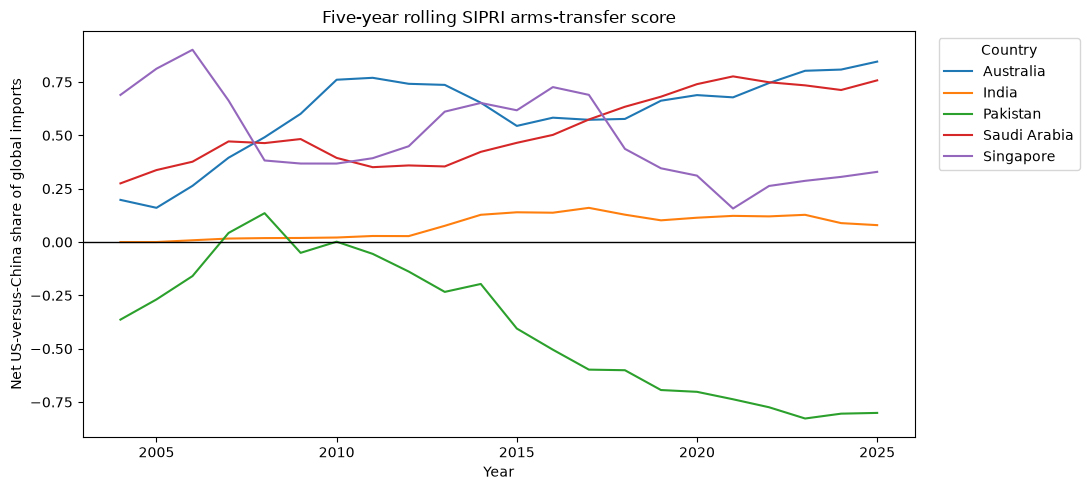

In [11]:
trajectory_iso3 = ["AUS", "IND", "PAK", "SAU", "SGP"]
trajectory_data = score_panel.loc[
    score_panel["iso3"].isin(trajectory_iso3),
    ["year", "preferred_country_name", "arms_transfer_score"],
]
trajectory_wide = trajectory_data.pivot(
    index="year",
    columns="preferred_country_name",
    values="arms_transfer_score",
)
trajectory_wide.plot(figsize=(11, 5))
plt.axhline(0, linewidth=1, color="black")
plt.title("Five-year rolling SIPRI arms-transfer score")
plt.xlabel("Year")
plt.ylabel("Net US-versus-China share of global imports")
plt.legend(title="Country", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 12. Low-volume threshold sensitivity

The low-volume threshold is diagnostic only. It does not alter the baseline score. This table shows how many scored country-years would be flagged under alternative thresholds.

In [12]:
volume_sensitivity = sipri.build_sensitivity(score_panel)
volume_sensitivity

,threshold,scored_country_years,flagged_country_years,flagged_share,countries_ever_flagged
0,25.0,2329,881,0.378274,108
1,50.0,2329,1112,0.477458,117
2,100.0,2329,1369,0.587806,127
3,250.0,2329,1684,0.723057,134


## 13. Displayed-zero sensitivity

SIPRI reports positive annual values below 0.5 million TIV as displayed zeroes. The baseline uses the midpoint 0.25. The cell below rebuilds the panel under 0, 0.25, and 0.5 substitutions and compares the resulting baseline scores.

In [13]:
def build_panel_for_rounded_zero(midpoint: float) -> pd.DataFrame:
    original = sipri.ROUNDED_ZERO_VALUE
    try:
        sipri.ROUNDED_ZERO_VALUE = midpoint
        frames = []
        for filepath, value_name in source_specs:
            evidence, _, _, _ = sipri.load_sipri_export(filepath, value_name)
            frames.append(evidence)
        annual, unmapped, _ = sipri.merge_and_map_sources(frames, lookup)
        if not unmapped.empty:
            raise ValueError(f"Unmapped names under sensitivity run: {unmapped}")
        annual_full = project_grid.merge(
            annual,
            on=["iso3", "year"],
            how="left",
            validate="one_to_one",
        )
        for column in sipri.VALUE_COLUMNS:
            annual_full[column] = annual_full[column].fillna(0.0)
        result = sipri.add_rolling_measures(annual_full)
        return result[["iso3", "year", "arms_transfer_score"]].rename(
            columns={"arms_transfer_score": f"score_midpoint_{midpoint:g}"}
        )
    finally:
        sipri.ROUNDED_ZERO_VALUE = original


midpoint_panels = [build_panel_for_rounded_zero(value) for value in (0.0, 0.25, 0.5)]
midpoint_comparison = midpoint_panels[0]
for frame in midpoint_panels[1:]:
    midpoint_comparison = midpoint_comparison.merge(
        frame,
        on=["iso3", "year"],
        how="outer",
        validate="one_to_one",
    )

midpoint_comparison["max_absolute_difference"] = (
    midpoint_comparison[
        ["score_midpoint_0", "score_midpoint_0.25", "score_midpoint_0.5"]
    ].max(axis=1)
    - midpoint_comparison[
        ["score_midpoint_0", "score_midpoint_0.25", "score_midpoint_0.5"]
    ].min(axis=1)
)

pd.Series(
    {
        "country-years compared": len(midpoint_comparison),
        "maximum absolute score difference": midpoint_comparison[
            "max_absolute_difference"
        ].max(),
        "country-years differing by more than 0.01": int(
            midpoint_comparison["max_absolute_difference"].gt(0.01).sum()
        ),
        "country-years differing by more than 0.05": int(
            midpoint_comparison["max_absolute_difference"].gt(0.05).sum()
        ),
    },
    name="value",
)

country-years compared                       4205.000000
maximum absolute score difference               0.333333
country-years differing by more than 0.01      97.000000
country-years differing by more than 0.05      28.000000
Name: value, dtype: float64

In [14]:
midpoint_comparison.nlargest(20, "max_absolute_difference")

,iso3,year,score_midpoint_0,score_midpoint_0.25,score_midpoint_0.5,max_absolute_difference
553,BRN,2007,0.000000,0.200000,0.333333,0.333333
1542,GUY,2006,-1.000000,-0.846154,-0.714286,0.285714
552,BRN,2006,0.000000,0.142857,0.250000,0.250000
554,BRN,2008,0.000000,0.111111,0.200000,0.200000
3355,SLE,2012,-1.000000,-0.888889,-0.800000,0.200000
1837,JAM,2015,0.000000,0.083333,0.166667,0.166667
550,BRN,2004,0.000000,0.076923,0.142857,0.142857
3049,PNG,2017,0.000000,-0.076923,-0.142857,0.142857
551,BRN,2005,0.000000,0.066667,0.125000,0.125000
2508,MLT,2004,1.000000,0.941176,0.888889,0.111111


## 14. Production decision checkpoint

### Decided

- Use five-year rolling SIPRI TIV values.
- Use the full 1996-2025 source history and publish 2004-2025.
- Treat blank cells as no identified delivery, coded zero.
- Represent displayed zeroes by 0.25 in the baseline specification.
- Use the project country master for universe and eligibility decisions.
- Use $(US-China)/Global$ as the baseline arms-transfer score.
- Retain pure direction, anchor exposure, anchor volume, and observation status as diagnostics.
- Assign a baseline score of zero when global imports exist but neither anchor supplied arms.
- Leave the baseline score missing when no global arms imports were observed.

### Provisional diagnostics

- `low_volume_flag` at 100 million TIV remains diagnostic and should not filter or alter baseline scores.
- Rounded-zero sensitivity should be retained in the audit trail.

### Validation requirements

- No unmapped state-like source names.
- No duplicate ISO3-year rows after mapping aggregation.
- Baseline and pure-direction scores remain within [-1, 1].
- The score identity equals direction multiplied by exposure.
- Any exposure above one must be audited rather than silently clipped.

## 15. Optional production build

The development analysis above does not write repository outputs. Once the review is complete, run the production builder from the repository root:

```bash
python src/data/build_sipri_arms_transfers.py
```

Then run the focused tests:

```bash
python -m pytest tests/test_sipri_arms_transfers.py -q
```